# Random Forest: Dr. Nattapon-aligned Phase-Grouped 5-Fold CV

This version keeps the original RF workflow but updates the comparison design:
- phase-grouped 5-fold CV,
- 30-candidate equal tuning budget,
- `class_weight=None` because RF fitting pixels are explicitly balanced,
- validation-only probability-threshold calibration,
- AUPRC reporting,
- final threshold locked before the independent test,
- larger RF fitting samples,
- Gini feature importance retained only as a descriptive output.


In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

from pathlib import Path
from collections import defaultdict
import gc
import json
import math
import random
import re
import time

import joblib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import rasterio

from PIL import Image

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve

print("NumPy version :", np.__version__)
print("Pandas version:", pd.__version__)




NumPy version : 2.5.2
Pandas version: 3.0.5


In [2]:
# ============================================================
# CELL 2 - MAIN CONFIGURATION
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path(r"D:\Experiment Ajarn")
IMAGE_DIR = BASE_DIR / "image"
LABEL_DIR = BASE_DIR / "label"
MANUAL_SPLIT_PATH = BASE_DIR / "manual_split.csv"

OUTPUT_DIR = BASE_DIR / "rf_5fold_cv_DrNattapon_output"
DATA_LIST_DIR = OUTPUT_DIR / "data_lists"
CV_DIR = OUTPUT_DIR / "cross_validation"
TUNING_DIR = OUTPUT_DIR / "hyperparameter_tuning"
MODEL_DIR = OUTPUT_DIR / "models"
PREDICTION_DIR = OUTPUT_DIR / "test_predictions"
ERROR_MAP_DIR = OUTPUT_DIR / "test_error_maps"
PLOT_DIR = OUTPUT_DIR / "plots"
FEATURE_IMPORTANCE_DIR = OUTPUT_DIR / "feature_importance"

for folder in [
    OUTPUT_DIR,
    DATA_LIST_DIR,
    CV_DIR,
    TUNING_DIR,
    MODEL_DIR,
    PREDICTION_DIR,
    ERROR_MAP_DIR,
    PLOT_DIR,
    FEATURE_IMPORTANCE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

TARGET_HEIGHT = 256
TARGET_WIDTH = 256
INPUT_CHANNELS = 3

# ------------------------------------------------------------
# Random Forest settings
# ------------------------------------------------------------
RF_N_JOBS = -1
RF_BOOTSTRAP = True
RF_CLASS_WEIGHT = None

# Number of hyperparameter combinations to evaluate.
N_CV_TRIALS = 30

# ------------------------------------------------------------
# Pixel sampling for Random Forest training
# ------------------------------------------------------------
# Tuning stage: smaller training sample for speed.
TUNING_ASH_PIXELS = 15000
TUNING_NONASH_PIXELS = 15000

# Best-hyperparameter 5-fold CV: larger training sample.
BEST_CV_ASH_PIXELS = 30000
BEST_CV_NONASH_PIXELS = 30000

# Final model trained on ALL Phase 1-13 images.
FINAL_ASH_PIXELS = 50000
FINAL_NONASH_PIXELS = 50000

# To prevent one image from dominating the sampled training set.
PER_IMAGE_CLASS_CAP = 5000

# During hyperparameter search, evaluate a reproducible subset of pixels
# from every validation image for speed.
# Set to None if you want ALL pixels for every tuning trial.
TUNING_EVAL_PIXELS_PER_IMAGE = 8192

# Final CV and final test use ALL pixels.
PREDICTION_CHUNK_SIZE = 200000

# Fixed phase-grouped folds.
FOLD_TO_PHASES = {
    1: [1, 13],          # 52 images
    2: [2, 12],          # 47 images
    3: [3, 7, 9],        # 46 images
    4: [4, 5, 8, 11],    # 49 images
    5: [6, 10],          # 51 images
}

PHASE_TO_FOLD = {
    phase: fold
    for fold, phases in FOLD_TO_PHASES.items()
    for phase in phases
}

# Correct total = 293 images: 245 train + 48 test.
EXPECTED_PHASE_COUNTS = {
    1: 26, 2: 37, 3: 17, 4: 14, 5: 10, 6: 9, 7: 11,
    8: 18, 9: 18, 10: 42, 11: 7, 12: 10, 13: 26,
    14: 29, 15: 6, 16: 13,
}

for required_path in [IMAGE_DIR, LABEL_DIR]:
    if not required_path.exists():
        raise FileNotFoundError(f"Directory not found: {required_path}")

if not MANUAL_SPLIT_PATH.exists():
    raise FileNotFoundError(f"manual_split.csv not found: {MANUAL_SPLIT_PATH}")

print("=" * 90)
print("RANDOM FOREST / PHASE-GROUPED 5-FOLD CV")
print("=" * 90)
print("Image directory :", IMAGE_DIR)
print("Label directory :", LABEL_DIR)
print("Output directory:", OUTPUT_DIR)
print("Target size     :", TARGET_HEIGHT, "x", TARGET_WIDTH)
print("CV trials       :", N_CV_TRIALS)
print("CV folds        :", len(FOLD_TO_PHASES))




RANDOM FOREST / PHASE-GROUPED 5-FOLD CV
Image directory : D:\Experiment Ajarn\image
Label directory : D:\Experiment Ajarn\label
Output directory: D:\Experiment Ajarn\rf_5fold_cv_DrNattapon_output
Target size     : 256 x 256
CV trials       : 30
CV folds        : 5


In [3]:
# ============================================================
# CELL 3 - TIMESTAMP AND PHASE FUNCTIONS
# ============================================================

def extract_timestamp(filename: str):
    """Extract YYYYMMDD_HHMM from an image/label filename."""
    match = re.search(r"(\d{8}_\d{4})", filename)
    return match.group(1) if match else None


def timestamp_to_phase(timestamp: str):
    """
    Assign each timestamp to eruption Phase 1-16.

    Important:
      20250618_0000 -> Phase 14
      20250802_0000 -> Phase 16
    """
    dt = pd.to_datetime(timestamp, format="%Y%m%d_%H%M")

    ranges = [
        (1,  "2024-11-08 21:30", "2024-11-09 10:00"),
        (2,  "2024-11-09 10:30", "2024-11-10 04:30"),
        (3,  "2024-11-10 05:00", "2024-11-10 13:00"),
        (4,  "2024-11-10 13:30", "2024-11-10 20:00"),
        (5,  "2024-11-11 03:00", "2024-11-11 07:30"),
        (6,  "2024-11-11 08:00", "2024-11-11 12:00"),
        (7,  "2024-11-11 12:30", "2024-11-11 17:30"),
        (8,  "2024-11-11 18:00", "2024-11-12 02:30"),
        (9,  "2024-11-12 03:00", "2024-11-12 11:30"),
        (10, "2024-11-12 12:00", "2024-11-13 08:30"),
        (11, "2024-11-13 09:00", "2024-11-13 12:00"),
        (12, "2024-11-13 14:30", "2024-11-13 19:00"),
        (13, "2024-11-13 19:30", "2024-11-14 08:00"),

        # Locked independent test data.
        (14, "2025-06-17 10:00", "2025-06-18 00:00"),
        (15, "2025-08-01 15:00", "2025-08-01 17:30"),
        (16, "2025-08-01 18:00", "2025-08-02 00:00"),
    ]

    for phase, start, end in ranges:
        if pd.Timestamp(start) <= dt <= pd.Timestamp(end):
            return phase

    return None


print("20250618_0000 -> Phase", timestamp_to_phase("20250618_0000"))
print("20250802_0000 -> Phase", timestamp_to_phase("20250802_0000"))




20250618_0000 -> Phase 14
20250802_0000 -> Phase 16


In [4]:
# ============================================================
# CELL 4 - FIND, MATCH, AND SPLIT IMAGE-LABEL PAIRS
# ============================================================

image_files = sorted(
    [
        p.resolve()
        for p in IMAGE_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in {".tif", ".tiff"}
    ],
    key=lambda p: p.name.lower(),
)

label_files = sorted(
    [
        p.resolve()
        for p in LABEL_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in {".tif", ".tiff", ".png"}
    ],
    key=lambda p: p.name.lower(),
)

if not image_files:
    raise FileNotFoundError(f"No TIFF images found in {IMAGE_DIR}")

if not label_files:
    raise FileNotFoundError(f"No label files found in {LABEL_DIR}")

image_groups = defaultdict(list)
for p in image_files:
    ts = extract_timestamp(p.name)
    if ts:
        image_groups[ts].append(p)

label_groups = defaultdict(list)
for p in label_files:
    ts = extract_timestamp(p.name)
    if ts:
        label_groups[ts].append(p)

image_dictionary = {
    ts: sorted(paths, key=lambda p: p.name.lower())[0]
    for ts, paths in image_groups.items()
}

label_dictionary = {
    ts: sorted(paths, key=lambda p: p.name.lower())[0]
    for ts, paths in label_groups.items()
}

matched_timestamps = sorted(set(image_dictionary) & set(label_dictionary))

if not matched_timestamps:
    raise ValueError("No matching image-label pairs were found.")

pairs_df = pd.DataFrame([
    {
        "timestamp": ts,
        "image_path": str(image_dictionary[ts]),
        "label_path": str(label_dictionary[ts]),
    }
    for ts in matched_timestamps
])

manual_split_df = pd.read_csv(
    MANUAL_SPLIT_PATH,
    dtype={"timestamp": str, "split": str},
)

required_columns = {"timestamp", "split"}
missing_columns = required_columns - set(manual_split_df.columns)

if missing_columns:
    raise ValueError(
        "manual_split.csv is missing columns: "
        + ", ".join(sorted(missing_columns))
    )

manual_split_df["timestamp"] = (
    manual_split_df["timestamp"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

manual_split_df["split"] = (
    manual_split_df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

manual_split_df["split"] = manual_split_df["split"].map({
    "train": "train",
    "training": "train",
    "tr": "train",
    "test": "test",
    "testing": "test",
    "te": "test",
})

if manual_split_df["split"].isna().any():
    raise ValueError(
        "manual_split.csv split must contain only train/test values."
    )

if manual_split_df["timestamp"].duplicated().any():
    raise ValueError("Duplicate timestamps found in manual_split.csv.")

split_df = pairs_df.merge(
    manual_split_df[["timestamp", "split"]],
    on="timestamp",
    how="left",
    validate="one_to_one",
)

if split_df["split"].isna().any():
    bad = split_df.loc[
        split_df["split"].isna(),
        ["timestamp", "image_path"]
    ]
    print(bad)
    raise ValueError(
        "Some matched pairs have no train/test assignment."
    )

split_df["phase"] = split_df["timestamp"].apply(timestamp_to_phase)

if split_df["phase"].isna().any():
    bad = split_df.loc[
        split_df["phase"].isna(),
        ["timestamp", "split"]
    ]
    print(bad.to_string(index=False))
    raise ValueError(
        "Some images could not be assigned to Phase 1-16."
    )

split_df["phase"] = split_df["phase"].astype(int)
split_df["phase_name"] = "Phase " + split_df["phase"].astype(str)

# Strict leakage checks.
bad_train = split_df[
    (split_df["split"] == "train")
    & (~split_df["phase"].between(1, 13))
]

bad_test = split_df[
    (split_df["split"] == "test")
    & (~split_df["phase"].between(14, 16))
]

if not bad_train.empty or not bad_test.empty:
    print("Unexpected train rows:")
    print(bad_train[["timestamp", "phase", "split"]])
    print("Unexpected test rows:")
    print(bad_test[["timestamp", "phase", "split"]])

    raise ValueError(
        "Train must contain only Phases 1-13 and "
        "test only Phases 14-16."
    )

split_df["fold"] = pd.Series(
    pd.NA,
    index=split_df.index,
    dtype="Int64",
)

train_mask = split_df["split"] == "train"

split_df.loc[train_mask, "fold"] = (
    split_df.loc[train_mask, "phase"]
    .map(PHASE_TO_FOLD)
    .astype("Int64")
)

if split_df.loc[train_mask, "fold"].isna().any():
    raise ValueError(
        "At least one training phase has no fold assignment."
    )

train_df = (
    split_df[split_df["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    split_df[split_df["split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

split_df.to_csv(
    DATA_LIST_DIR / "all_pairs_with_phase_and_fold.csv",
    index=False,
)

train_df.to_csv(
    DATA_LIST_DIR / "training_files_with_folds.csv",
    index=False,
)

test_df.to_csv(
    DATA_LIST_DIR / "testing_files_with_phases.csv",
    index=False,
)

print("=" * 90)
print("TRAIN / TEST SPLIT")
print("=" * 90)
print("Training images:", len(train_df))
print("Testing images :", len(test_df))
print("Total images   :", len(split_df))




TRAIN / TEST SPLIT
Training images: 245
Testing images : 48
Total images   : 293


In [5]:
# ============================================================
# CELL 5 - READ ASH-RGB IMAGE AND BINARY LABEL
# ============================================================

def read_tiff_rgb(image_path) -> np.ndarray:
    """
    Read TIFF and return H x W x 3 float32 array in 0-255 scale.
    """
    if isinstance(image_path, bytes):
        image_path = image_path.decode("utf-8")

    with rasterio.open(str(image_path)) as src:
        image = src.read()

    image = np.transpose(image, (1, 2, 0))
    channel_count = image.shape[-1]

    if channel_count == 1:
        image = np.repeat(image, 3, axis=-1)

    elif channel_count == 2:
        image = np.concatenate(
            [image, np.zeros_like(image[:, :, :1])],
            axis=-1,
        )

    elif channel_count > 3:
        image = image[:, :, :3]

    image = np.nan_to_num(
        image.astype(np.float32),
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )

    image_min = float(np.min(image))
    image_max = float(np.max(image))

    # Same normalization logic as the Hybrid notebook.
    if image_min >= 0 and image_max <= 1:
        image = image * 255.0

    elif image_min >= 0 and image_max <= 255:
        pass

    elif image_min >= 0 and image_max <= 65535:
        image = image / 65535.0 * 255.0

    elif image_max > image_min:
        image = (
            (image - image_min)
            / (image_max - image_min)
            * 255.0
        )

    else:
        image = np.zeros_like(
            image,
            dtype=np.float32,
        )

    image = np.clip(
        image,
        0.0,
        255.0,
    ).astype(np.float32)

    # Resize if necessary.
    if image.shape[:2] != (TARGET_HEIGHT, TARGET_WIDTH):
        image = np.asarray(
            Image.fromarray(
                image.astype(np.uint8)
            ).resize(
                (TARGET_WIDTH, TARGET_HEIGHT),
                resample=Image.Resampling.BILINEAR,
            ),
            dtype=np.float32,
        )

    return image


def read_binary_label(label_path) -> np.ndarray:
    """
    Return H x W uint8 binary mask:
      0 = non-ash
      1 = ash

    Supports:
      - single-band 0/1
      - single-band 0/255
      - RGB red=ash / blue=non-ash
    """
    if isinstance(label_path, bytes):
        label_path = label_path.decode("utf-8")

    label_path = Path(str(label_path))

    if label_path.suffix.lower() in {".tif", ".tiff"}:
        with rasterio.open(label_path) as src:
            raw = src.read()

        if raw.shape[0] == 1:
            label_array = raw[0]
        else:
            label_array = np.transpose(
                raw[:3],
                (1, 2, 0),
            )

    else:
        with Image.open(label_path) as img:
            label_array = np.array(img)

    if label_array.ndim == 3:
        rgb = label_array[:, :, :3].astype(np.float32)

        red = rgb[:, :, 0]
        green = rgb[:, :, 1]
        blue = rgb[:, :, 2]

        binary_label = (
            (red > green)
            & (red > blue)
            & (red >= 128)
        ).astype(np.uint8)

    elif label_array.ndim == 2:
        arr = label_array.astype(np.float32)
        unique_values = np.unique(arr)

        if np.all(np.isin(unique_values, [0, 1])):
            binary_label = arr.astype(np.uint8)
        else:
            binary_label = (
                arr >= 128
            ).astype(np.uint8)

    else:
        raise ValueError(
            f"Unsupported label shape: {label_array.shape}"
        )

    if binary_label.shape != (TARGET_HEIGHT, TARGET_WIDTH):
        binary_label = np.asarray(
            Image.fromarray(
                binary_label.astype(np.uint8)
            ).resize(
                (TARGET_WIDTH, TARGET_HEIGHT),
                resample=Image.Resampling.NEAREST,
            ),
            dtype=np.uint8,
        )

        binary_label = (
            binary_label >= 1
        ).astype(np.uint8)

    return binary_label


def load_image_and_mask(row):
    image = read_tiff_rgb(row.image_path)
    mask = read_binary_label(row.label_path)

    if image.shape[:2] != mask.shape:
        raise ValueError(
            f"Image/mask shape mismatch for {row.timestamp}: "
            f"{image.shape} vs {mask.shape}"
        )

    return image, mask




In [6]:
# ============================================================
# CELL 6 - CALCULATE PHASE/FOLD ASH PERCENTAGES
# ============================================================

def label_pixel_counts(label_path):
    mask = read_binary_label(label_path)

    ash = int(np.sum(mask == 1))
    non_ash = int(np.sum(mask == 0))
    total = ash + non_ash

    return ash, non_ash, total


pixel_stats = []

for _, row in split_df.iterrows():
    ash, non_ash, total = label_pixel_counts(
        row["label_path"]
    )
    pixel_stats.append(
        (ash, non_ash, total)
    )

split_df[
    [
        "ash_pixels",
        "non_ash_pixels",
        "total_pixels",
    ]
] = pd.DataFrame(
    pixel_stats,
    index=split_df.index,
)

split_df["ash_percent"] = (
    split_df["ash_pixels"]
    / split_df["total_pixels"].clip(lower=1)
    * 100.0
)

train_df = (
    split_df[split_df["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    split_df[split_df["split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

phase_summary = (
    split_df
    .groupby(
        ["phase", "phase_name", "split"],
        as_index=False,
    )
    .agg(
        number_of_images=("timestamp", "count"),
        total_pixels=("total_pixels", "sum"),
        ash_pixels=("ash_pixels", "sum"),
        non_ash_pixels=("non_ash_pixels", "sum"),
        mean_image_ash_percent=("ash_percent", "mean"),
        std_image_ash_percent=("ash_percent", "std"),
    )
)

phase_summary["phase_ash_percent"] = (
    phase_summary["ash_pixels"]
    / phase_summary["total_pixels"].clip(lower=1)
    * 100.0
)

phase_summary["phase_non_ash_percent"] = (
    100.0
    - phase_summary["phase_ash_percent"]
)

phase_summary.to_csv(
    DATA_LIST_DIR / "phase_summary.csv",
    index=False,
)

fold_rows = []

for fold, phases in FOLD_TO_PHASES.items():
    fold_df = train_df[
        train_df["fold"] == fold
    ]

    total = int(
        fold_df["total_pixels"].sum()
    )

    ash = int(
        fold_df["ash_pixels"].sum()
    )

    fold_rows.append({
        "fold": fold,
        "validation_phases": ", ".join(
            f"Phase {p}"
            for p in phases
        ),
        "validation_images": len(fold_df),
        "training_images": len(train_df) - len(fold_df),
        "validation_ash_percent":
            ash / max(total, 1) * 100,
        "validation_non_ash_percent":
            100 - ash / max(total, 1) * 100,
    })

fold_summary = pd.DataFrame(
    fold_rows
)

fold_summary.to_csv(
    DATA_LIST_DIR / "fold_summary.csv",
    index=False,
)

print("\nPHASE SUMMARY")
print(
    phase_summary[
        [
            "phase_name",
            "split",
            "number_of_images",
            "phase_ash_percent",
            "phase_non_ash_percent",
        ]
    ]
    .round(3)
    .to_string(index=False)
)

print("\nFOLD SUMMARY")
print(
    fold_summary
    .round(3)
    .to_string(index=False)
)

print("\nCOUNT CHECK")

actual_counts = (
    split_df
    .groupby("phase")
    .size()
    .to_dict()
)

for phase in range(1, 17):
    actual = actual_counts.get(
        phase,
        0,
    )

    expected = EXPECTED_PHASE_COUNTS.get(
        phase
    )

    status = (
        "OK"
        if actual == expected
        else "CHECK"
    )

    print(
        f"Phase {phase:2d}: "
        f"actual={actual:3d} "
        f"expected={expected:3d} "
        f"{status}"
    )





PHASE SUMMARY
phase_name split  number_of_images  phase_ash_percent  phase_non_ash_percent
   Phase 1 train                26              6.829                 93.171
   Phase 2 train                37              4.109                 95.891
   Phase 3 train                17              0.862                 99.138
   Phase 4 train                14              1.653                 98.347
   Phase 5 train                10              2.047                 97.953
   Phase 6 train                 9              2.539                 97.461
   Phase 7 train                11              5.323                 94.677
   Phase 8 train                18              3.561                 96.439
   Phase 9 train                18              3.149                 96.851
  Phase 10 train                42              2.206                 97.794
  Phase 11 train                 7              0.444                 99.556
  Phase 12 train                10              0.238        

In [7]:
# ============================================================
# CELL 7 - METRICS
# ============================================================

def confusion_counts(actual, predicted):
    actual = (
        np.asarray(actual)
        .astype(np.uint8)
        .reshape(-1)
    )

    predicted = (
        np.asarray(predicted)
        .astype(np.uint8)
        .reshape(-1)
    )

    tp = int(
        np.sum(
            (actual == 1)
            & (predicted == 1)
        )
    )

    tn = int(
        np.sum(
            (actual == 0)
            & (predicted == 0)
        )
    )

    fp = int(
        np.sum(
            (actual == 0)
            & (predicted == 1)
        )
    )

    fn = int(
        np.sum(
            (actual == 1)
            & (predicted == 0)
        )
    )

    return tp, tn, fp, fn


def metrics_from_counts(tp, tn, fp, fn):
    total = tp + tn + fp + fn

    accuracy = (
        (tp + tn)
        / max(total, 1)
    )

    precision = (
        tp
        / max(tp + fp, 1)
    )

    recall_pod = (
        tp
        / max(tp + fn, 1)
    )

    f1_dice = (
        2 * tp
        / max(
            2 * tp + fp + fn,
            1,
        )
    )

    iou = (
        tp
        / max(
            tp + fp + fn,
            1,
        )
    )

    far = (
        fp
        / max(tp + fp, 1)
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall_pod": recall_pod,
        "f1_dice": f1_dice,
        "iou": iou,
        "false_alarm_ratio": far,
        "true_positive": int(tp),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
    }




def find_best_probability_threshold(y_true, probabilities):
    """Choose the validation-only probability threshold maximizing F1/Dice."""
    y_true = np.asarray(y_true, dtype=np.uint8).reshape(-1)
    probabilities = np.asarray(probabilities, dtype=float).reshape(-1)

    if np.unique(y_true).size < 2:
        raise ValueError("Validation data must contain both classes.")

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities,
    )

    if thresholds.size == 0:
        return 0.5, np.nan

    precision_t = precision[:-1]
    recall_t = recall[:-1]

    f1 = (
        2.0 * precision_t * recall_t
        / np.maximum(precision_t + recall_t, 1e-12)
    )

    best_index = int(np.nanargmax(f1))

    return (
        float(thresholds[best_index]),
        float(f1[best_index]),
    )


In [8]:
# ============================================================
# CELL 8 - PIXEL SAMPLING FOR RANDOM FOREST TRAINING
# ============================================================

def sample_class_pixels(
    dataframe,
    target_ash_pixels,
    target_nonash_pixels,
    seed,
):
    """
    Build a reproducible pixel sample from ONLY the provided dataframe.

    Each pixel feature:
        [R, G, B]

    This function limits the number of candidate pixels contributed by
    each image so that a small number of ash-rich images do not dominate
    the Random Forest training sample.
    """
    rng = np.random.default_rng(seed)

    ash_candidates = []
    nonash_candidates = []

    for row in dataframe.itertuples(index=False):
        image, mask = load_image_and_mask(row)

        X = image.reshape(
            -1,
            INPUT_CHANNELS,
        ).astype(np.float32)

        y = mask.reshape(-1)

        ash_idx = np.flatnonzero(
            y == 1
        )

        nonash_idx = np.flatnonzero(
            y == 0
        )

        if ash_idx.size > 0:
            n = min(
                PER_IMAGE_CLASS_CAP,
                ash_idx.size,
            )

            selected = rng.choice(
                ash_idx,
                size=n,
                replace=False,
            )

            ash_candidates.append(
                X[selected]
            )

        if nonash_idx.size > 0:
            n = min(
                PER_IMAGE_CLASS_CAP,
                nonash_idx.size,
            )

            selected = rng.choice(
                nonash_idx,
                size=n,
                replace=False,
            )

            nonash_candidates.append(
                X[selected]
            )

    if not ash_candidates:
        raise ValueError(
            "No ash pixels found in the training dataframe."
        )

    if not nonash_candidates:
        raise ValueError(
            "No non-ash pixels found in the training dataframe."
        )

    X_ash = np.concatenate(
        ash_candidates,
        axis=0,
    )

    X_nonash = np.concatenate(
        nonash_candidates,
        axis=0,
    )

    if len(X_ash) > target_ash_pixels:
        idx = rng.choice(
            len(X_ash),
            size=target_ash_pixels,
            replace=False,
        )
        X_ash = X_ash[idx]

    if len(X_nonash) > target_nonash_pixels:
        idx = rng.choice(
            len(X_nonash),
            size=target_nonash_pixels,
            replace=False,
        )
        X_nonash = X_nonash[idx]

    y_ash = np.ones(
        len(X_ash),
        dtype=np.uint8,
    )

    y_nonash = np.zeros(
        len(X_nonash),
        dtype=np.uint8,
    )

    X_train = np.concatenate(
        [X_ash, X_nonash],
        axis=0,
    )

    y_train = np.concatenate(
        [y_ash, y_nonash],
        axis=0,
    )

    order = rng.permutation(
        len(y_train)
    )

    X_train = X_train[order]
    y_train = y_train[order]

    sample_info = {
        "sampled_ash_pixels": int(
            np.sum(y_train == 1)
        ),
        "sampled_nonash_pixels": int(
            np.sum(y_train == 0)
        ),
        "sampled_total_pixels": int(
            len(y_train)
        ),
    }

    return X_train, y_train, sample_info




In [9]:
# ============================================================
# CELL 9 - RANDOM FOREST MODEL BUILDER
# ============================================================

def parse_max_depth(value):
    if value is None:
        return None

    text = str(value).strip().lower()
    if text in {"none", "nan", ""}:
        return None

    return int(float(value))


def parse_max_features(value):
    if value is None:
        return None

    text = str(value).strip().lower()
    if text in {"none", "nan", ""}:
        return None

    return str(value)


def build_rf_model(params, random_state=SEED):
    """
    Build a RandomForestClassifier.

    Random Forest does not require StandardScaler because tree splits
    are invariant to monotonic feature scaling.
    """
    return RandomForestClassifier(
        n_estimators=int(params["n_estimators"]),
        criterion=str(params["criterion"]),
        max_depth=parse_max_depth(params["max_depth"]),
        min_samples_split=int(params["min_samples_split"]),
        min_samples_leaf=int(params["min_samples_leaf"]),
        max_features=parse_max_features(params["max_features"]),
        bootstrap=RF_BOOTSTRAP,
        class_weight=RF_CLASS_WEIGHT,
        random_state=random_state,
        n_jobs=RF_N_JOBS,
    )



In [10]:
# ============================================================
# CELL 10 - PROBABILITY, THRESHOLD, AND EVALUATION FUNCTIONS
# ============================================================

def predict_probability_flat(
    model,
    X,
    chunk_size=PREDICTION_CHUNK_SIZE,
):
    """Return P(ash=1) in chunks."""
    X = np.asarray(X, dtype=np.float32)

    probabilities = np.empty(
        len(X),
        dtype=np.float32,
    )

    for start in range(
        0,
        len(X),
        chunk_size,
    ):
        end = min(
            start + chunk_size,
            len(X),
        )

        probabilities[start:end] = (
            model.predict_proba(
                X[start:end]
            )[:, 1]
            .astype(np.float32)
        )

    return probabilities


def collect_dataframe_probabilities(
    model,
    dataframe,
    max_pixels_per_image=None,
    seed=SEED,
):
    """
    Collect labels and continuous RF ash probabilities.

    Validation sampling is random across all pixels, not class-balanced,
    so the natural validation prevalence is approximately retained.
    """
    rng = np.random.default_rng(seed)

    labels_all = []
    probabilities_all = []

    for row in dataframe.itertuples(index=False):
        image, actual = load_image_and_mask(row)

        X = image.reshape(
            -1,
            INPUT_CHANNELS,
        ).astype(np.float32)

        y = actual.reshape(-1).astype(np.uint8)

        if (
            max_pixels_per_image is not None
            and len(y) > max_pixels_per_image
        ):
            idx = rng.choice(
                len(y),
                size=max_pixels_per_image,
                replace=False,
            )

            X = X[idx]
            y = y[idx]

        probabilities = predict_probability_flat(
            model,
            X,
        )

        labels_all.append(y)
        probabilities_all.append(probabilities)

    return (
        np.concatenate(labels_all),
        np.concatenate(probabilities_all),
    )


def evaluate_probabilities(
    y_true,
    probabilities,
    threshold,
):
    y_true = np.asarray(
        y_true,
        dtype=np.uint8,
    ).reshape(-1)

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    ).reshape(-1)

    predicted = (
        probabilities >= threshold
    ).astype(np.uint8)

    tp, tn, fp, fn = confusion_counts(
        y_true,
        predicted,
    )

    metrics = metrics_from_counts(
        tp,
        tn,
        fp,
        fn,
    )

    if np.unique(y_true).size >= 2:
        auprc = average_precision_score(
            y_true,
            probabilities,
        )
    else:
        auprc = np.nan

    metrics["auprc"] = float(auprc)
    metrics["probability_threshold"] = float(threshold)

    return metrics


def calibrate_and_evaluate_on_dataframe(
    model,
    dataframe,
    max_pixels_per_image=None,
    seed=SEED,
):
    """
    Find the best threshold only from the current validation fold,
    then calculate validation metrics and AUPRC.
    """
    y_true, probabilities = collect_dataframe_probabilities(
        model,
        dataframe,
        max_pixels_per_image=max_pixels_per_image,
        seed=seed,
    )

    threshold, calibration_f1 = find_best_probability_threshold(
        y_true,
        probabilities,
    )

    metrics = evaluate_probabilities(
        y_true,
        probabilities,
        threshold,
    )

    metrics["threshold_calibration_f1"] = float(
        calibration_f1
    )

    return metrics


In [11]:
# ============================================================
# CELL 11 - GENERATE REPRODUCIBLE RF HYPERPARAMETER CANDIDATES
# ============================================================

def generate_hyperparameter_candidates(
    n_trials,
    seed=SEED,
):
    """
    Reproducible Randomized Search.

    class_weight is deliberately NOT tuned because the fitting sample
    is already balanced and RF_CLASS_WEIGHT is fixed to None.
    """
    rng = np.random.default_rng(seed)

    search_space = {
        "n_estimators": [200, 300, 500, 800],
        "criterion": ["gini", "entropy"],
        "max_depth": ["None", 10, 20, 30, 40, 50],
        "min_samples_split": [2, 5, 10, 15],
        "min_samples_leaf": [1, 2, 5, 10],
        "max_features": ["sqrt", "log2", "None"],
    }

    candidates = [{
        "trial_id": 1,
        "n_estimators": 500,
        "criterion": "gini",
        "max_depth": "None",
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
    }]

    used = {
        (500, "gini", "None", 2, 1, "sqrt")
    }

    attempts = 0

    while (
        len(candidates) < n_trials
        and attempts < 20000
    ):
        attempts += 1

        max_depth = rng.choice(
            search_space["max_depth"]
        )

        if str(max_depth).lower() == "none":
            max_depth = "None"
        else:
            max_depth = int(max_depth)

        candidate = {
            "trial_id":
                len(candidates) + 1,
            "n_estimators":
                int(rng.choice(
                    search_space["n_estimators"]
                )),
            "criterion":
                str(rng.choice(
                    search_space["criterion"]
                )),
            "max_depth":
                max_depth,
            "min_samples_split":
                int(rng.choice(
                    search_space["min_samples_split"]
                )),
            "min_samples_leaf":
                int(rng.choice(
                    search_space["min_samples_leaf"]
                )),
            "max_features":
                str(rng.choice(
                    search_space["max_features"]
                )),
        }

        key = (
            candidate["n_estimators"],
            candidate["criterion"],
            str(candidate["max_depth"]),
            candidate["min_samples_split"],
            candidate["min_samples_leaf"],
            candidate["max_features"],
        )

        if key in used:
            continue

        used.add(key)
        candidates.append(candidate)

    if len(candidates) < n_trials:
        raise RuntimeError(
            "Could not generate enough unique RF candidates."
        )

    return pd.DataFrame(candidates)


candidate_df = generate_hyperparameter_candidates(
    N_CV_TRIALS,
    seed=SEED,
)

candidate_df.to_csv(
    TUNING_DIR / "cv_hyperparameter_candidates.csv",
    index=False,
)

print(candidate_df.to_string(index=False))


 trial_id  n_estimators criterion max_depth  min_samples_split  min_samples_leaf max_features
        1           500      gini      None                  2                 1         sqrt
        2           800   entropy      None                  5                 2         None
        3           500      gini      None                  2                 5         None
        4           800   entropy        40                 15                 5         sqrt
        5           300   entropy        50                  5                 1         None
        6           500      gini        40                 15                 5         log2
        7           200      gini        20                 10                10         sqrt
        8           800      gini        50                 10                 1         None
        9           300      gini        40                 15                 2         None
       10           800   entropy        40                 

In [12]:
# ============================================================
# CELL 12 - 5-FOLD CV RF HYPERPARAMETER TUNING
# VALIDATION-ONLY THRESHOLD CALIBRATION + AUPRC
# ============================================================

cv_tuning_records = []

for _, candidate in candidate_df.iterrows():
    trial_id = int(
        candidate["trial_id"]
    )

    params = {
        "n_estimators":
            int(candidate["n_estimators"]),
        "criterion":
            candidate["criterion"],
        "max_depth":
            candidate["max_depth"],
        "min_samples_split":
            int(candidate["min_samples_split"]),
        "min_samples_leaf":
            int(candidate["min_samples_leaf"]),
        "max_features":
            candidate["max_features"],
    }

    print("\n" + "=" * 100)
    print(
        f"RF HYPERPARAMETER TRIAL "
        f"{trial_id}/{len(candidate_df)}"
    )
    print("=" * 100)
    print(params)

    for fold in sorted(FOLD_TO_PHASES):
        fold_train_df = (
            train_df[
                train_df["fold"] != fold
            ]
            .copy()
            .reset_index(drop=True)
        )

        fold_val_df = (
            train_df[
                train_df["fold"] == fold
            ]
            .copy()
            .reset_index(drop=True)
        )

        print("\n" + "-" * 90)
        print(
            f"Trial {trial_id} | Fold {fold}"
        )
        print(
            "Train images:",
            len(fold_train_df),
        )
        print(
            "Val images  :",
            len(fold_val_df),
        )
        print(
            "Val phases  :",
            FOLD_TO_PHASES[fold],
        )

        # Balanced pixel sampling is used only for RF fitting.
        X_train, y_train, sample_info = sample_class_pixels(
            fold_train_df,
            target_ash_pixels=TUNING_ASH_PIXELS,
            target_nonash_pixels=TUNING_NONASH_PIXELS,
            seed=SEED + trial_id * 100 + fold,
        )

        print(
            "Training pixel sample:",
            sample_info,
        )

        model = build_rf_model(
            params,
            random_state=SEED + trial_id * 100 + fold,
        )

        start_time = time.time()

        model.fit(
            X_train,
            y_train,
        )

        training_seconds = (
            time.time()
            - start_time
        )

        # Threshold calibration is done only on this validation fold.
        # Validation sampling is NOT class-balanced.
        fold_metrics = calibrate_and_evaluate_on_dataframe(
            model,
            fold_val_df,
            max_pixels_per_image=TUNING_EVAL_PIXELS_PER_IMAGE,
            seed=SEED + fold,
        )

        record = {
            "trial_id":
                trial_id,
            "fold":
                fold,
            "validation_phases":
                ", ".join(
                    str(p)
                    for p in FOLD_TO_PHASES[fold]
                ),
            "training_images":
                len(fold_train_df),
            "validation_images":
                len(fold_val_df),
            "training_seconds":
                training_seconds,
            "class_weight":
                RF_CLASS_WEIGHT,
            **params,
            **sample_info,
            **fold_metrics,
        }

        cv_tuning_records.append(
            record
        )

        print(
            f"Threshold="
            f"{fold_metrics['probability_threshold']:.5f} | "
            f"AUPRC="
            f"{fold_metrics['auprc']:.4f} | "
            f"Dice="
            f"{fold_metrics['f1_dice']:.4f} | "
            f"IoU="
            f"{fold_metrics['iou']:.4f} | "
            f"POD="
            f"{fold_metrics['recall_pod']:.4f} | "
            f"FAR="
            f"{fold_metrics['false_alarm_ratio']:.4f}"
        )

        del model
        del X_train
        del y_train
        gc.collect()


cv_tuning_df = pd.DataFrame(
    cv_tuning_records
)

cv_tuning_df.to_csv(
    TUNING_DIR / "cv_tuning_fold_results.csv",
    index=False,
)


cv_trial_summary = (
    cv_tuning_df
    .groupby(
        "trial_id",
        as_index=False,
    )
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_precision=("precision", "mean"),
        std_precision=("precision", "std"),
        mean_recall_pod=("recall_pod", "mean"),
        std_recall_pod=("recall_pod", "std"),
        mean_f1_dice=("f1_dice", "mean"),
        std_f1_dice=("f1_dice", "std"),
        mean_iou=("iou", "mean"),
        std_iou=("iou", "std"),
        mean_false_alarm_ratio=(
            "false_alarm_ratio",
            "mean",
        ),
        std_false_alarm_ratio=(
            "false_alarm_ratio",
            "std",
        ),
        mean_auprc=("auprc", "mean"),
        std_auprc=("auprc", "std"),
        mean_probability_threshold=(
            "probability_threshold",
            "mean",
        ),
        std_probability_threshold=(
            "probability_threshold",
            "std",
        ),
        mean_training_seconds=(
            "training_seconds",
            "mean",
        ),
    )
)

cv_trial_summary = (
    cv_trial_summary
    .merge(
        candidate_df,
        on="trial_id",
        how="left",
    )
)

# Primary ranking = highest mean validation Dice/F1.
# Secondary ranking = highest mean validation AUPRC.
cv_trial_summary = (
    cv_trial_summary
    .sort_values(
        [
            "mean_f1_dice",
            "mean_auprc",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

cv_trial_summary.to_csv(
    TUNING_DIR / "cv_tuning_trial_summary.csv",
    index=False,
)

print("\n" + "=" * 100)
print("RANDOM FOREST HYPERPARAMETER TUNING SUMMARY")
print("=" * 100)

print(
    cv_trial_summary[
        [
            "trial_id",
            "n_estimators",
            "criterion",
            "max_depth",
            "min_samples_split",
            "min_samples_leaf",
            "max_features",
            "mean_probability_threshold",
            "mean_auprc",
            "mean_f1_dice",
            "std_f1_dice",
            "mean_iou",
            "mean_recall_pod",
            "mean_false_alarm_ratio",
        ]
    ]
    .round(5)
    .to_string(index=False)
)



RF HYPERPARAMETER TRIAL 1/30
{'n_estimators': 500, 'criterion': 'gini', 'max_depth': 'None', 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'}

------------------------------------------------------------------------------------------
Trial 1 | Fold 1
Train images: 193
Val images  : 52
Val phases  : [1, 13]
Training pixel sample: {'sampled_ash_pixels': 15000, 'sampled_nonash_pixels': 15000, 'sampled_total_pixels': 30000}
Threshold=0.68533 | AUPRC=0.5049 | Dice=0.4968 | IoU=0.3305 | POD=0.4252 | FAR=0.4025

------------------------------------------------------------------------------------------
Trial 1 | Fold 2
Train images: 198
Val images  : 47
Val phases  : [2, 12]
Training pixel sample: {'sampled_ash_pixels': 15000, 'sampled_nonash_pixels': 15000, 'sampled_total_pixels': 30000}
Threshold=0.94450 | AUPRC=0.4347 | Dice=0.4232 | IoU=0.2684 | POD=0.3654 | FAR=0.4972

------------------------------------------------------------------------------------------
Trial 1

In [13]:
# ============================================================
# CELL 13 - SELECT AND SAVE BEST RANDOM FOREST HYPERPARAMETERS
# ============================================================

best_trial_id = int(
    cv_trial_summary.iloc[0]["trial_id"]
)

best_row = candidate_df[
    candidate_df["trial_id"] == best_trial_id
].iloc[0]

best_params = {
    "n_estimators":
        int(best_row["n_estimators"]),
    "criterion":
        str(best_row["criterion"]),
    "max_depth":
        (
            "None"
            if str(best_row["max_depth"]).lower()
            in {"none", "nan"}
            else int(float(best_row["max_depth"]))
        ),
    "min_samples_split":
        int(best_row["min_samples_split"]),
    "min_samples_leaf":
        int(best_row["min_samples_leaf"]),
    "max_features":
        str(best_row["max_features"]),
}

best_params_json = {
    "best_trial_id":
        best_trial_id,
    "tuning_budget":
        N_CV_TRIALS,
    "bootstrap":
        RF_BOOTSTRAP,
    "class_weight":
        RF_CLASS_WEIGHT,
    **best_params,
}

with open(
    TUNING_DIR / "best_hyperparameters.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        best_params_json,
        f,
        indent=4,
    )

pd.DataFrame([
    best_params_json
]).to_csv(
    TUNING_DIR / "best_hyperparameters.csv",
    index=False,
)

print("=" * 90)
print("BEST CROSS-VALIDATED RANDOM FOREST HYPERPARAMETERS")
print("=" * 90)

for key, value in best_params_json.items():
    print(
        f"{key:25s}: {value}"
    )


BEST CROSS-VALIDATED RANDOM FOREST HYPERPARAMETERS
best_trial_id            : 18
tuning_budget            : 30
bootstrap                : True
class_weight             : None
n_estimators             : 500
criterion                : entropy
max_depth                : 10
min_samples_split        : 2
min_samples_leaf         : 10
max_features             : sqrt


In [14]:
# ============================================================
# CELL 14 - FULL 5-FOLD CV USING BEST RF HYPERPARAMETERS
# ALL VALIDATION PIXELS + FINAL THRESHOLD CALIBRATION
# ============================================================

best_hp_cv_records = []

for fold in sorted(FOLD_TO_PHASES):
    fold_train_df = (
        train_df[
            train_df["fold"] != fold
        ]
        .copy()
        .reset_index(drop=True)
    )

    fold_val_df = (
        train_df[
            train_df["fold"] == fold
        ]
        .copy()
        .reset_index(drop=True)
    )

    print("\n" + "=" * 100)
    print(
        f"BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD {fold}"
    )
    print("=" * 100)
    print(
        "Validation phases:",
        FOLD_TO_PHASES[fold],
    )

    X_train, y_train, sample_info = sample_class_pixels(
        fold_train_df,
        target_ash_pixels=BEST_CV_ASH_PIXELS,
        target_nonash_pixels=BEST_CV_NONASH_PIXELS,
        seed=SEED + 1000 + fold,
    )

    model = build_rf_model(
        best_params,
        random_state=SEED + 1000 + fold,
    )

    start_time = time.time()

    model.fit(
        X_train,
        y_train,
    )

    training_seconds = (
        time.time()
        - start_time
    )

    # Use ALL validation pixels here.
    fold_metrics = calibrate_and_evaluate_on_dataframe(
        model,
        fold_val_df,
        max_pixels_per_image=None,
        seed=SEED,
    )

    best_hp_cv_records.append({
        "fold":
            fold,
        "validation_phases":
            ", ".join(
                str(p)
                for p in FOLD_TO_PHASES[fold]
            ),
        "training_images":
            len(fold_train_df),
        "validation_images":
            len(fold_val_df),
        "training_seconds":
            training_seconds,
        **sample_info,
        **fold_metrics,
    })

    print(
        f"Threshold="
        f"{fold_metrics['probability_threshold']:.5f} | "
        f"AUPRC="
        f"{fold_metrics['auprc']:.4f} | "
        f"Accuracy="
        f"{fold_metrics['accuracy']:.4f} | "
        f"Precision="
        f"{fold_metrics['precision']:.4f} | "
        f"POD="
        f"{fold_metrics['recall_pod']:.4f} | "
        f"Dice="
        f"{fold_metrics['f1_dice']:.4f} | "
        f"IoU="
        f"{fold_metrics['iou']:.4f} | "
        f"FAR="
        f"{fold_metrics['false_alarm_ratio']:.4f}"
    )

    del model
    del X_train
    del y_train
    gc.collect()


best_hp_cv_df = pd.DataFrame(
    best_hp_cv_records
)

best_hp_cv_df.to_csv(
    CV_DIR / "best_hyperparameters_5fold_results.csv",
    index=False,
)


# ------------------------------------------------------------
# LOCK FINAL THRESHOLD BEFORE TEST
# ------------------------------------------------------------

FINAL_PROBABILITY_THRESHOLD = float(
    best_hp_cv_df[
        "probability_threshold"
    ].median()
)

threshold_summary = pd.DataFrame([
    {
        "threshold_aggregation":
            "median_of_5_validation_optimal_thresholds",
        "final_probability_threshold":
            FINAL_PROBABILITY_THRESHOLD,
        "mean_threshold":
            best_hp_cv_df[
                "probability_threshold"
            ].mean(),
        "std_threshold":
            best_hp_cv_df[
                "probability_threshold"
            ].std(ddof=1),
        "min_threshold":
            best_hp_cv_df[
                "probability_threshold"
            ].min(),
        "max_threshold":
            best_hp_cv_df[
                "probability_threshold"
            ].max(),
    }
])

threshold_summary.to_csv(
    CV_DIR / "final_threshold_from_5fold_cv.csv",
    index=False,
)

with open(
    CV_DIR / "final_threshold_from_5fold_cv.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "method":
                "median_of_5_validation_optimal_thresholds",
            "final_probability_threshold":
                FINAL_PROBABILITY_THRESHOLD,
            "fold_thresholds":
                [
                    float(value)
                    for value in best_hp_cv_df[
                        "probability_threshold"
                    ].tolist()
                ],
        },
        f,
        indent=4,
    )


metrics_for_summary = [
    "accuracy",
    "precision",
    "recall_pod",
    "f1_dice",
    "iou",
    "false_alarm_ratio",
    "auprc",
    "probability_threshold",
]

summary_rows = []

for metric in metrics_for_summary:
    summary_rows.append({
        "metric":
            metric,
        "mean":
            best_hp_cv_df[metric].mean(),
        "std":
            best_hp_cv_df[metric].std(ddof=1),
        "min":
            best_hp_cv_df[metric].min(),
        "max":
            best_hp_cv_df[metric].max(),
    })

best_hp_cv_summary = pd.DataFrame(
    summary_rows
)

best_hp_cv_summary.to_csv(
    CV_DIR / "best_hyperparameters_5fold_summary.csv",
    index=False,
)

print("\n" + "=" * 100)
print("FINAL RANDOM FOREST 5-FOLD CV RESULTS")
print("=" * 100)

print(
    best_hp_cv_df[
        [
            "fold",
            "validation_phases",
            "validation_images",
            "probability_threshold",
            "auprc",
            "accuracy",
            "precision",
            "recall_pod",
            "f1_dice",
            "iou",
            "false_alarm_ratio",
        ]
    ]
    .round(5)
    .to_string(index=False)
)

print("\nMEAN ± SD")

for _, row in best_hp_cv_summary.iterrows():
    print(
        f"{row['metric']:25s}: "
        f"{row['mean']:.5f} ± {row['std']:.5f}"
    )

print("\nLOCKED FINAL RF PROBABILITY THRESHOLD")
print(
    f"{FINAL_PROBABILITY_THRESHOLD:.6f}"
)
print(
    "(Median of five validation-optimal thresholds; "
    "test data not used.)"
)



BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD 1
Validation phases: [1, 13]
Threshold=0.62641 | AUPRC=0.5259 | Accuracy=0.9673 | Precision=0.5829 | POD=0.4419 | Dice=0.5027 | IoU=0.3357 | FAR=0.4171

BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD 2
Validation phases: [2, 12]
Threshold=0.86799 | AUPRC=0.5186 | Accuracy=0.9679 | Precision=0.5126 | POD=0.4399 | Dice=0.4735 | IoU=0.3102 | FAR=0.4874

BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD 3
Validation phases: [3, 7, 9]
Threshold=0.95101 | AUPRC=0.7810 | Accuracy=0.9837 | Precision=0.7133 | POD=0.7072 | Dice=0.7102 | IoU=0.5507 | FAR=0.2867

BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD 4
Validation phases: [4, 5, 8, 11]
Threshold=0.96616 | AUPRC=0.6983 | Accuracy=0.9838 | Precision=0.6406 | POD=0.6428 | Dice=0.6417 | IoU=0.4724 | FAR=0.3594

BEST-HYPERPARAMETER RANDOM FOREST CV | FOLD 5
Validation phases: [6, 10]
Threshold=0.96356 | AUPRC=0.7791 | Accuracy=0.9876 | Precision=0.7366 | POD=0.7059 | Dice=0.7209 | IoU=0.5636 | FAR=0.2634

FINAL 

In [15]:
# ============================================================
# CELL 15 - FINAL RF TRAINING ON ALL PHASE 1-13 IMAGES
# ============================================================

print("\n" + "=" * 100)
print("FINAL RANDOM FOREST TRAINING ON ALL PHASE 1-13 IMAGES")
print("=" * 100)

X_final, y_final, final_sample_info = sample_class_pixels(
    train_df,
    target_ash_pixels=FINAL_ASH_PIXELS,
    target_nonash_pixels=FINAL_NONASH_PIXELS,
    seed=SEED + 5000,
)

print(
    "Final training pixel sample:",
    final_sample_info,
)

final_model = build_rf_model(
    best_params,
    random_state=SEED + 5000,
)

start_time = time.time()

final_model.fit(
    X_final,
    y_final,
)

final_training_seconds = (
    time.time()
    - start_time
)

FINAL_MODEL_PATH = (
    MODEL_DIR
    / "best_cv_tuned_random_forest.joblib"
)

joblib.dump(
    final_model,
    FINAL_MODEL_PATH,
)

pd.DataFrame([
    {
        "training_images":
            len(train_df),
        "training_seconds":
            final_training_seconds,
        **final_sample_info,
        **best_params,
        "bootstrap":
            RF_BOOTSTRAP,
        "class_weight":
            RF_CLASS_WEIGHT,
        "final_probability_threshold":
            FINAL_PROBABILITY_THRESHOLD,
        "threshold_source":
            "median_of_5_validation_optimal_thresholds",
    }
]).to_csv(
    MODEL_DIR / "final_training_summary.csv",
    index=False,
)

print("Final model saved to:")
print(FINAL_MODEL_PATH)

print(
    "Locked RF probability threshold:",
    f"{FINAL_PROBABILITY_THRESHOLD:.6f}",
)

del X_final
del y_final
gc.collect()



FINAL RANDOM FOREST TRAINING ON ALL PHASE 1-13 IMAGES
Final training pixel sample: {'sampled_ash_pixels': 50000, 'sampled_nonash_pixels': 50000, 'sampled_total_pixels': 100000}
Final model saved to:
D:\Experiment Ajarn\rf_5fold_cv_DrNattapon_output\models\best_cv_tuned_random_forest.joblib
Locked RF probability threshold: 0.951015


0

In [16]:
# ============================================================
# CELL 16 - FINAL TEST PREDICTIONS + PER-IMAGE METRICS + AUPRC
# ============================================================

def create_red_blue_mask(binary_mask):
    color = np.zeros(
        (*binary_mask.shape, 3),
        dtype=np.uint8,
    )

    color[binary_mask == 0] = [0, 0, 255]
    color[binary_mask == 1] = [255, 0, 0]

    return color


def create_error_map(actual, predicted):
    error_map = np.zeros(
        (*actual.shape, 3),
        dtype=np.uint8,
    )

    tn = (actual == 0) & (predicted == 0)
    tp = (actual == 1) & (predicted == 1)
    fp = (actual == 0) & (predicted == 1)
    fn = (actual == 1) & (predicted == 0)

    error_map[tn] = [0, 0, 0]
    error_map[tp] = [0, 180, 0]
    error_map[fp] = [255, 0, 0]
    error_map[fn] = [255, 255, 0]

    return error_map


prediction_records = []

test_labels_all = []
test_probabilities_all = []

test_labels_by_phase = defaultdict(list)
test_probabilities_by_phase = defaultdict(list)


print("\n" + "=" * 100)
print("FINAL INDEPENDENT RANDOM FOREST TEST: PHASES 14-16")
print("=" * 100)

print(
    "Number of test images:",
    len(test_df),
)

print(
    "LOCKED threshold:",
    f"{FINAL_PROBABILITY_THRESHOLD:.6f}",
)


for image_index, row in enumerate(
    test_df.itertuples(index=False),
    start=1,
):
    image, actual = load_image_and_mask(
        row
    )

    h, w, c = image.shape

    X_test_image = image.reshape(
        -1,
        c,
    ).astype(np.float32)

    y_test_image = actual.reshape(
        -1
    ).astype(np.uint8)

    probabilities = predict_probability_flat(
        final_model,
        X_test_image,
    )

    predicted_flat = (
        probabilities
        >= FINAL_PROBABILITY_THRESHOLD
    ).astype(np.uint8)

    predicted = predicted_flat.reshape(
        h,
        w,
    )

    tp, tn, fp, fn = confusion_counts(
        actual,
        predicted,
    )

    metrics = metrics_from_counts(
        tp,
        tn,
        fp,
        fn,
    )

    if np.unique(y_test_image).size >= 2:
        image_auprc = average_precision_score(
            y_test_image,
            probabilities,
        )
    else:
        image_auprc = np.nan

    metrics["auprc"] = float(
        image_auprc
    )

    metrics["probability_threshold"] = float(
        FINAL_PROBABILITY_THRESHOLD
    )

    test_labels_all.append(
        y_test_image
    )

    test_probabilities_all.append(
        probabilities
    )

    test_labels_by_phase[
        int(row.phase)
    ].append(
        y_test_image
    )

    test_probabilities_by_phase[
        int(row.phase)
    ].append(
        probabilities
    )

    total_pixels = max(
        tp + tn + fp + fn,
        1,
    )

    ground_truth_ash_percent = (
        (tp + fn)
        / total_pixels
        * 100
    )

    predicted_ash_percent = (
        (tp + fp)
        / total_pixels
        * 100
    )

    prediction_records.append({
        "timestamp":
            row.timestamp,
        "phase":
            int(row.phase),
        "phase_name":
            row.phase_name,
        "ground_truth_ash_percent":
            ground_truth_ash_percent,
        "predicted_ash_percent":
            predicted_ash_percent,
        **metrics,
    })

    print(
        f"[{image_index:02d}/{len(test_df)}] "
        f"{row.timestamp} | "
        f"Phase {int(row.phase)} | "
        f"AUPRC={metrics['auprc']:.4f} | "
        f"IoU={metrics['iou']:.4f} | "
        f"Dice={metrics['f1_dice']:.4f} | "
        f"POD={metrics['recall_pod']:.4f} | "
        f"FAR={metrics['false_alarm_ratio']:.4f}"
    )

    Image.fromarray(
        predicted * 255
    ).save(
        PREDICTION_DIR
        / (
            f"{row.timestamp}_"
            f"phase{int(row.phase)}_"
            f"rf_prediction_binary.png"
        )
    )

    prediction_color = create_red_blue_mask(
        predicted
    )

    actual_color = create_red_blue_mask(
        actual
    )

    Image.fromarray(
        prediction_color
    ).save(
        PREDICTION_DIR
        / (
            f"{row.timestamp}_"
            f"phase{int(row.phase)}_"
            f"rf_prediction_color.png"
        )
    )

    error_map = create_error_map(
        actual,
        predicted,
    )

    Image.fromarray(
        error_map
    ).save(
        ERROR_MAP_DIR
        / (
            f"{row.timestamp}_"
            f"phase{int(row.phase)}_"
            f"rf_error_map.png"
        )
    )

    raw_image = np.clip(
        image,
        0,
        255,
    ).astype(np.uint8)

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5),
    )

    axes[0].imshow(raw_image)
    axes[0].set_title(
        f"Himawari-9 Ash RGB\n"
        f"{row.timestamp} | Phase {int(row.phase)}"
    )
    axes[0].axis("off")

    axes[1].imshow(actual_color)
    axes[1].set_title(
        "Ground Truth\n"
        "Red = Ash, Blue = Non-ash"
    )
    axes[1].axis("off")

    axes[2].imshow(prediction_color)
    axes[2].set_title(
        "Random Forest Prediction\n"
        f"IoU={metrics['iou']:.3f}, "
        f"Dice={metrics['f1_dice']:.3f}"
    )
    axes[2].axis("off")

    axes[3].imshow(error_map)
    axes[3].set_title("Error Map")
    axes[3].axis("off")

    axes[3].legend(
        handles=[
            Patch(
                facecolor="black",
                label="TN",
            ),
            Patch(
                facecolor="green",
                label="TP",
            ),
            Patch(
                facecolor="red",
                label="FP",
            ),
            Patch(
                facecolor="yellow",
                label="FN",
            ),
        ],
        loc="lower center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=4,
        frameon=False,
    )

    plt.tight_layout()

    plt.savefig(
        ERROR_MAP_DIR
        / (
            f"{row.timestamp}_"
            f"phase{int(row.phase)}_"
            f"rf_comparison_error_map.png"
        ),
        dpi=250,
        bbox_inches="tight",
    )

    plt.close(fig)


test_per_image_df = pd.DataFrame(
    prediction_records
)

test_per_image_df.to_csv(
    OUTPUT_DIR / "test_per_image_metrics.csv",
    index=False,
)

TEST_Y_ALL = np.concatenate(
    test_labels_all
)

TEST_PROBABILITIES_ALL = np.concatenate(
    test_probabilities_all
)

print("\n" + "=" * 100)
print("RANDOM FOREST TEST PER-IMAGE RESULTS")
print("=" * 100)

print(
    test_per_image_df
    .round(5)
    .to_string(index=False)
)



FINAL INDEPENDENT RANDOM FOREST TEST: PHASES 14-16
Number of test images: 48
LOCKED threshold: 0.951015
[01/48] 20250617_1000 | Phase 14 | AUPRC=0.0275 | IoU=0.0287 | Dice=0.0558 | POD=0.0817 | FAR=0.9576
[02/48] 20250617_1030 | Phase 14 | AUPRC=0.1277 | IoU=0.0844 | Dice=0.1557 | POD=0.1383 | FAR=0.8219
[03/48] 20250617_1100 | Phase 14 | AUPRC=0.1508 | IoU=0.0893 | Dice=0.1640 | POD=0.1261 | FAR=0.7656
[04/48] 20250617_1130 | Phase 14 | AUPRC=0.2309 | IoU=0.1267 | Dice=0.2249 | POD=0.1679 | FAR=0.6594
[05/48] 20250617_1200 | Phase 14 | AUPRC=0.3911 | IoU=0.2200 | Dice=0.3607 | POD=0.2790 | FAR=0.4901
[06/48] 20250617_1230 | Phase 14 | AUPRC=0.4966 | IoU=0.2887 | Dice=0.4480 | POD=0.3582 | FAR=0.4019
[07/48] 20250617_1300 | Phase 14 | AUPRC=0.5821 | IoU=0.3574 | Dice=0.5265 | POD=0.4484 | FAR=0.3623
[08/48] 20250617_1330 | Phase 14 | AUPRC=0.7032 | IoU=0.4334 | Dice=0.6047 | POD=0.5161 | FAR=0.2699
[09/48] 20250617_1400 | Phase 14 | AUPRC=0.7867 | IoU=0.5509 | Dice=0.7104 | POD=0.6500

In [17]:
# ============================================================
# CELL 17 - TEST METRICS BY PHASE 14, 15, AND 16 + AUPRC
# ============================================================

phase_test_records = []

for phase in [
    14,
    15,
    16,
]:
    phase_df = (
        test_per_image_df[
            test_per_image_df["phase"] == phase
        ]
        .copy()
    )

    if phase_df.empty:
        print(
            f"WARNING: No test images found "
            f"for Phase {phase}"
        )
        continue

    tp = int(
        phase_df["true_positive"].sum()
    )

    tn = int(
        phase_df["true_negative"].sum()
    )

    fp = int(
        phase_df["false_positive"].sum()
    )

    fn = int(
        phase_df["false_negative"].sum()
    )

    pooled = metrics_from_counts(
        tp,
        tn,
        fp,
        fn,
    )

    phase_y = np.concatenate(
        test_labels_by_phase[phase]
    )

    phase_probabilities = np.concatenate(
        test_probabilities_by_phase[phase]
    )

    if np.unique(phase_y).size >= 2:
        phase_auprc = average_precision_score(
            phase_y,
            phase_probabilities,
        )
    else:
        phase_auprc = np.nan

    total = max(
        tp + tn + fp + fn,
        1,
    )

    phase_test_records.append({
        "phase":
            phase,
        "phase_name":
            f"Phase {phase}",
        "number_of_images":
            len(phase_df),
        "probability_threshold":
            FINAL_PROBABILITY_THRESHOLD,
        "ground_truth_ash_percent":
            (tp + fn) / total * 100,
        "predicted_ash_percent":
            (tp + fp) / total * 100,
        "pooled_auprc":
            phase_auprc,
        "mean_image_auprc":
            phase_df["auprc"].mean(),
        "std_image_auprc":
            phase_df["auprc"].std(ddof=1),
        "mean_image_dice":
            phase_df["f1_dice"].mean(),
        "std_image_dice":
            phase_df["f1_dice"].std(ddof=1),
        "mean_image_iou":
            phase_df["iou"].mean(),
        "std_image_iou":
            phase_df["iou"].std(ddof=1),
        **pooled,
    })


phase_test_df = pd.DataFrame(
    phase_test_records
)

phase_test_df.to_csv(
    OUTPUT_DIR / "test_metrics_by_phase_14_15_16.csv",
    index=False,
)

print("\n" + "=" * 100)
print("RANDOM FOREST TEST RESULTS BY PHASE")
print("=" * 100)

print(
    phase_test_df
    .round(5)
    .to_string(index=False)
)



RANDOM FOREST TEST RESULTS BY PHASE
 phase phase_name  number_of_images  probability_threshold  ground_truth_ash_percent  predicted_ash_percent  pooled_auprc  mean_image_auprc  std_image_auprc  mean_image_dice  std_image_dice  mean_image_iou  std_image_iou  accuracy  precision  recall_pod  f1_dice     iou  false_alarm_ratio  true_positive  true_negative  false_positive  false_negative
    14   Phase 14                29                0.95101                  11.81093                9.86860       0.66685           0.60374          0.22902          0.55642         0.19904         0.40836        0.17372   0.91860    0.68599     0.57318  0.62453 0.45405            0.31401         128662        1617177           58895           95810
    15   Phase 15                 6                0.95101                   2.93681                0.39393       0.58656           0.61603          0.24381          0.25103         0.28335         0.17373        0.22520   0.97455    0.99677     0.13370  0.23

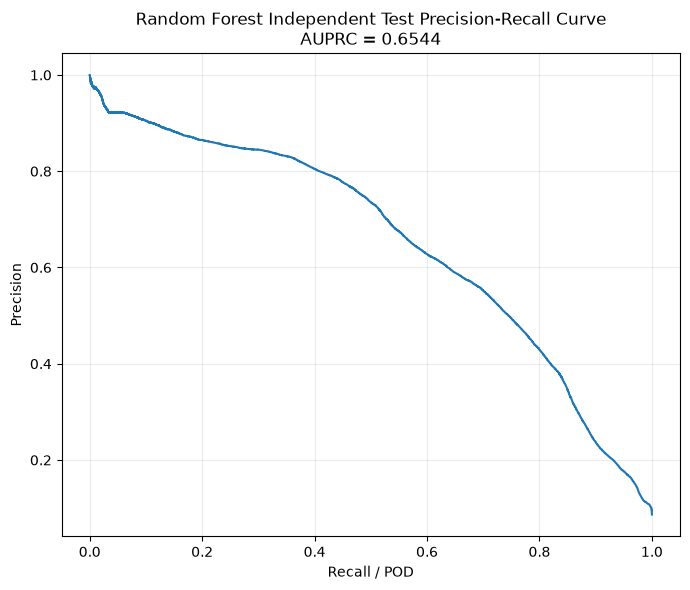


OVERALL LOCKED RANDOM FOREST TEST RESULT
 number_of_images   phases  ground_truth_ash_percent  predicted_ash_percent  accuracy  precision  recall_pod  f1_dice     iou  false_alarm_ratio  true_positive  true_negative  false_positive  false_negative   auprc  probability_threshold
               48 14,15,16                   8.67392                6.41546   0.93981    0.70688     0.52283  0.60108 0.42968            0.29312         142658        2813715           59155          130200 0.65441                0.95101


In [18]:
# ============================================================
# CELL 18 - OVERALL INDEPENDENT TEST METRICS + POOLED AUPRC
# ============================================================

tp = int(
    test_per_image_df["true_positive"].sum()
)

tn = int(
    test_per_image_df["true_negative"].sum()
)

fp = int(
    test_per_image_df["false_positive"].sum()
)

fn = int(
    test_per_image_df["false_negative"].sum()
)

overall_test_metrics = metrics_from_counts(
    tp,
    tn,
    fp,
    fn,
)

overall_test_auprc = (
    average_precision_score(
        TEST_Y_ALL,
        TEST_PROBABILITIES_ALL,
    )
    if np.unique(TEST_Y_ALL).size >= 2
    else np.nan
)

overall_test_metrics[
    "auprc"
] = float(
    overall_test_auprc
)

overall_test_metrics[
    "probability_threshold"
] = float(
    FINAL_PROBABILITY_THRESHOLD
)

total = max(
    tp + tn + fp + fn,
    1,
)

overall_test_df = pd.DataFrame([
    {
        "number_of_images":
            len(test_per_image_df),
        "phases":
            "14,15,16",
        "ground_truth_ash_percent":
            (tp + fn) / total * 100,
        "predicted_ash_percent":
            (tp + fp) / total * 100,
        **overall_test_metrics,
    }
])

overall_test_df.to_csv(
    OUTPUT_DIR / "test_metrics_overall.csv",
    index=False,
)


# Pooled Precision-Recall curve
pr_precision, pr_recall, _ = precision_recall_curve(
    TEST_Y_ALL,
    TEST_PROBABILITIES_ALL,
)

pr_curve_df = pd.DataFrame({
    "recall":
        pr_recall,
    "precision":
        pr_precision,
})

pr_curve_df.to_csv(
    OUTPUT_DIR / "test_precision_recall_curve.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    pr_recall,
    pr_precision,
)

ax.set_xlabel(
    "Recall / POD"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Random Forest Independent Test Precision-Recall Curve\n"
    f"AUPRC = {overall_test_auprc:.4f}"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "test_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("\n" + "=" * 100)
print("OVERALL LOCKED RANDOM FOREST TEST RESULT")
print("=" * 100)

print(
    overall_test_df
    .round(5)
    .to_string(index=False)
)


In [19]:
# ============================================================
# CELL 19 - SAVE COMPACT CV VS TEST SUMMARY
# ============================================================

cv_summary_wide = {}

for _, row in best_hp_cv_summary.iterrows():
    cv_summary_wide[
        f"cv_{row['metric']}_mean"
    ] = row["mean"]

    cv_summary_wide[
        f"cv_{row['metric']}_std"
    ] = row["std"]

final_summary = pd.DataFrame([
    {
        "model":
            "Random_Forest",
        "best_trial_id":
            best_trial_id,
        "tuning_budget":
            N_CV_TRIALS,
        "class_weight":
            RF_CLASS_WEIGHT,
        "threshold_method":
            "median_of_5_validation_optimal_thresholds",
        "final_probability_threshold":
            FINAL_PROBABILITY_THRESHOLD,
        **best_params,
        **cv_summary_wide,
        **{
            f"test_{k}": v
            for k, v in overall_test_metrics.items()
            if k not in {
                "true_positive",
                "true_negative",
                "false_positive",
                "false_negative",
            }
        },
    }
])

final_summary.to_csv(
    OUTPUT_DIR / "cv_and_independent_test_summary.csv",
    index=False,
)

print("\nAll outputs saved under:")
print(OUTPUT_DIR)

print("\nImportant files:")
print(" - hyperparameter_tuning/cv_hyperparameter_candidates.csv")
print(" - hyperparameter_tuning/cv_tuning_fold_results.csv")
print(" - hyperparameter_tuning/cv_tuning_trial_summary.csv")
print(" - hyperparameter_tuning/best_hyperparameters.csv")
print(" - cross_validation/best_hyperparameters_5fold_results.csv")
print(" - cross_validation/best_hyperparameters_5fold_summary.csv")
print(" - cross_validation/final_threshold_from_5fold_cv.csv")
print(" - models/best_cv_tuned_random_forest.joblib")
print(" - models/final_training_summary.csv")
print(" - test_per_image_metrics.csv")
print(" - test_metrics_by_phase_14_15_16.csv")
print(" - test_metrics_overall.csv")
print(" - test_precision_recall_curve.csv")
print(" - plots/test_precision_recall_curve.png")
print(" - cv_and_independent_test_summary.csv")
print(" - test_error_maps/*.png")



All outputs saved under:
D:\Experiment Ajarn\rf_5fold_cv_DrNattapon_output

Important files:
 - hyperparameter_tuning/cv_hyperparameter_candidates.csv
 - hyperparameter_tuning/cv_tuning_fold_results.csv
 - hyperparameter_tuning/cv_tuning_trial_summary.csv
 - hyperparameter_tuning/best_hyperparameters.csv
 - cross_validation/best_hyperparameters_5fold_results.csv
 - cross_validation/best_hyperparameters_5fold_summary.csv
 - cross_validation/final_threshold_from_5fold_cv.csv
 - models/best_cv_tuned_random_forest.joblib
 - models/final_training_summary.csv
 - test_per_image_metrics.csv
 - test_metrics_by_phase_14_15_16.csv
 - test_metrics_overall.csv
 - test_precision_recall_curve.csv
 - plots/test_precision_recall_curve.png
 - cv_and_independent_test_summary.csv
 - test_error_maps/*.png



DESCRIPTIVE RANDOM FOREST GINI FEATURE IMPORTANCE
Do NOT use this ranking as the input-selection criterion.
feature  gini_importance
      G         0.375000
      R         0.334536
      B         0.290464


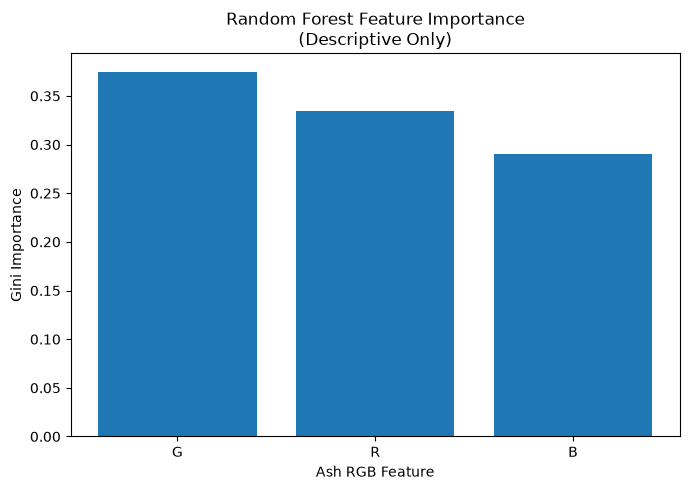

In [20]:
# ============================================================
# CELL 20 - DESCRIPTIVE RF GINI FEATURE IMPORTANCE ONLY
# ============================================================
#
# IMPORTANT:
# This output is descriptive only and is NOT used for feature selection.
# A separate phase-grouped input-ablation experiment should be used
# for comparing Ash RGB vs raw thermal inputs.
# ============================================================

FEATURE_NAMES = [
    "R",
    "G",
    "B",
]

feature_importance = np.asarray(
    final_model.feature_importances_,
    dtype=float,
)

feature_importance_df = pd.DataFrame({
    "feature":
        FEATURE_NAMES,
    "gini_importance":
        feature_importance,
}).sort_values(
    "gini_importance",
    ascending=False,
).reset_index(drop=True)

feature_importance_df.to_csv(
    FEATURE_IMPORTANCE_DIR
    / "final_rf_gini_feature_importance_DESCRIPTIVE_ONLY.csv",
    index=False,
)

print(
    "\nDESCRIPTIVE RANDOM FOREST GINI FEATURE IMPORTANCE"
)

print(
    "Do NOT use this ranking as the input-selection criterion."
)

print(
    feature_importance_df
    .round(6)
    .to_string(index=False)
)

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    feature_importance_df["feature"],
    feature_importance_df["gini_importance"],
)

ax.set_xlabel(
    "Ash RGB Feature"
)

ax.set_ylabel(
    "Gini Importance"
)

ax.set_title(
    "Random Forest Feature Importance\n"
    "(Descriptive Only)"
)

plt.tight_layout()

plt.savefig(
    FEATURE_IMPORTANCE_DIR
    / "final_rf_gini_feature_importance_DESCRIPTIVE_ONLY.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
